# Clustering in Python 

1. **Hierarchical clustering**
2. **K‑means**
3. **Model‑based clustering (Gaussian Mixture Models)**


### 0) Setup — Imports & Basic Settings

In [ ]:
# Imports for data frame manipulation and numerical operations
import numpy as np
import pandas as pd

# For plotting
import matplotlib.pyplot as plt

# For data and clustering models
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# For evaluation metrics
from sklearn.metrics import silhouette_score


# For hierarchical dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram



### 1) Dataset — Iris (features only)

We'll use the classic **Iris** dataset. It has 150 flowers with 4 measurements:
- sepal length, sepal width, petal length, petal width (all in cm).

We **won't** use the species labels for fitting (clustering is unsupervised),
but they can help us interpret results later.

In [22]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target # the true labels (not used in clustering)
X.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**Exercise 2 (1–2 min).**  
Show the **shape** (rows, columns) of `X` and print simple **summary statistics**.

In [ ]:
# Your code here



### Quick visualization of two features

We'll make a simple scatter plot of **petal length** vs **petal width**.
We don't use the labels, as we will be doing clustering, which is unsupervised.

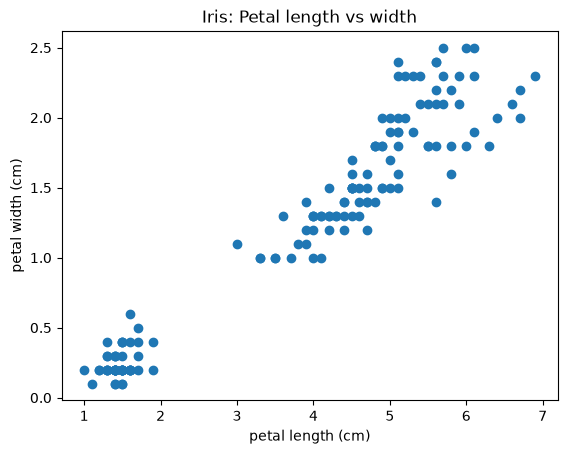

In [34]:
fig, ax = plt.subplots()
ax.scatter(X["petal length (cm)"], X["petal width (cm)"])
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Iris: Petal length vs width")
plt.show()

**Task (2–3 min).**  
Make the same kind of scatter plot but for **sepal length** vs **sepal width**.
(Label the axes and add a title.)

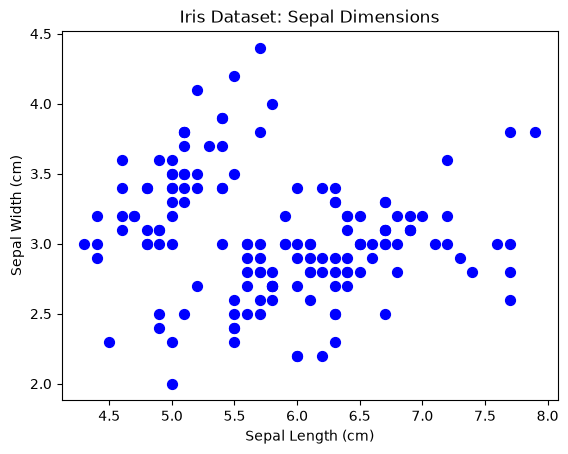

In [35]:
# Your code here
fig, ax = plt.subplots()
ax.scatter(
    X["sepal length (cm)"], 
    X["sepal width (cm)"],
    c='blue',
    s=50
)
ax.set_xlabel("Sepal Length (cm)")
ax.set_ylabel("Sepal Width (cm)")
ax.set_title("Iris Dataset: Sepal Dimensions")
plt.show()

### 2) Standardize features (good practice)

Many clustering methods work better if features are on a similar scale.
We'll standardize to **zero mean** and **unit variance**.

In [26]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Before scaling, first two rows:\n", X.iloc[:2].values)
print("\nAfter scaling, first two rows:\n", X_scaled[:2])

Before scaling, first two rows:
 [[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]]

After scaling, first two rows:
 [[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]]


### 3) Hierarchical (agglomerative) clustering

**Idea:** Start with each point as its own cluster, then iteratively merge the two closest clusters.
We’ll start with **complete linkage**.


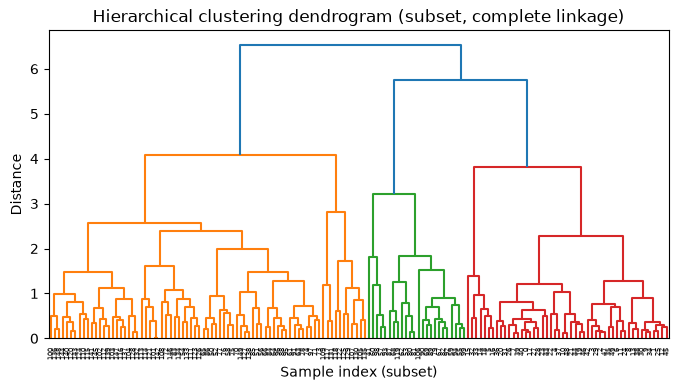

In [27]:
Z = linkage(X_scaled, method="complete")
fig, ax = plt.subplots(figsize=(8, 4))
dend = dendrogram(Z, ax=ax)

ax.set_title("Hierarchical clustering dendrogram (subset, complete linkage)")
ax.set_xlabel("Sample index (subset)")
ax.set_ylabel("Distance")
plt.show()

Now fit **AgglomerativeClustering** to easier get the information about the clusters labels. 

Agglomerative labels (first 10): [1 1 1 1 1 1 1 1 1 1]


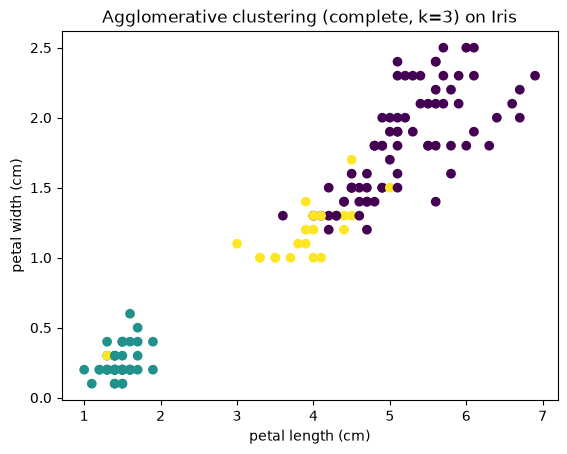

In [28]:
agg = AgglomerativeClustering(n_clusters=3, linkage="complete")
agg_labels = agg.fit_predict(X_scaled)

print("Agglomerative labels (first 10):", agg_labels[:10])

# Visualize clusters in 2D using petal length vs width
fig, ax = plt.subplots()
ax.scatter(X["petal length (cm)"], X["petal width (cm)"], c=agg_labels)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("Agglomerative clustering (complete, k=3) on Iris")
plt.show()



**Task (3–4 min).**  
Change the **linkage** to `"Ward"` and then `"simple"`. Compare shapes of the dendrograms.

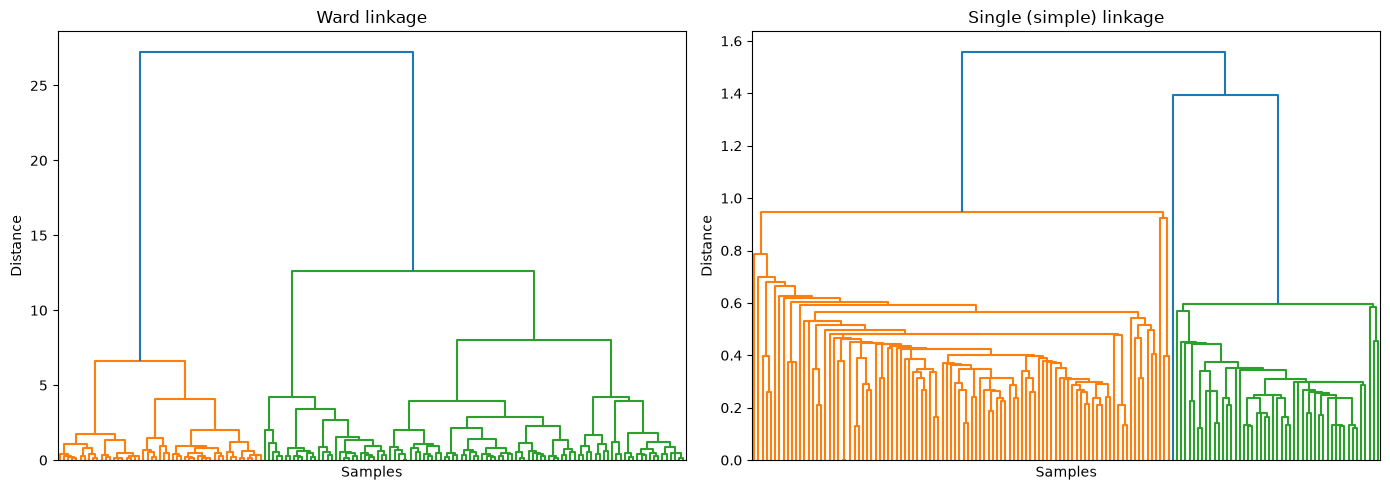

In [29]:
Z_ward = linkage(X_scaled, method="ward")
Z_single = linkage(X_scaled, method="single")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

dendrogram(Z_ward, ax=axes[0], no_labels=True)
axes[0].set_title("Ward linkage")
axes[0].set_xlabel("Samples")
axes[0].set_ylabel("Distance")

dendrogram(Z_single, ax=axes[1], no_labels=True)
axes[1].set_title("Single (simple) linkage")
axes[1].set_xlabel("Samples")
axes[1].set_ylabel("Distance")

plt.tight_layout()
plt.show()

## 4) K‑means clustering

**Idea:** Pick `k` centers and assign each point to the nearest center. Recompute centers, repeat.

We'll try **k=3** on Iris.

Cluster labels (first 10): [1 2 2 2 1 1 1 1 2 2]
Inertia (lower can be better): 191.02473685317972


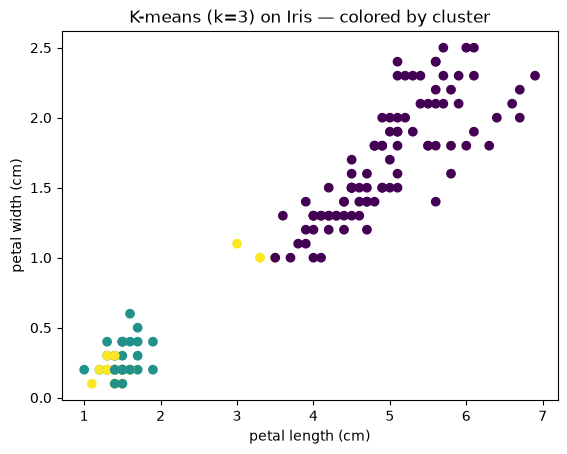

In [30]:
kmeans = KMeans(n_clusters=3, n_init="auto", random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("Cluster labels (first 10):", kmeans_labels[:10])
print("Inertia (lower can be better):", kmeans.inertia_)

# Visualize clusters in 2D using petal length vs width
fig, ax = plt.subplots()
ax.scatter(X["petal length (cm)"], X["petal width (cm)"], c=kmeans_labels)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title("K-means (k=3) on Iris — colored by cluster")
plt.show()


**Exercise 5 (3–4 min).**  
Change `k` to 2 and then 4 and re‑run the cell.  
Also, visualize the clustered data using sepal width and sepal lenth

Check how many clusters are optimal according to Silhouttel index.

In [31]:
silhouette_scores = {}
for k in [2,3,4]:
    km = KMeans(n_clusters=k, n_init="auto", random_state=0)
    labels = km.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)   
    print("k =", k, "silhouette:", silhouette_scores[k])
print("Best k:", max(silhouette_scores, key=silhouette_scores.get))




k = 2 silhouette: 0.5817500491982808
k = 3 silhouette: 0.45994823920518635
k = 4 silhouette: 0.38694104154427816
Best k: 2


## 6) Model‑based clustering — Gaussian Mixture Models (GMM)

**Idea:** Assume data are generated from a mixture of Gaussian distributions.
(Fit via **maximum likelihood** and assign points to the mixture component with highest probability.
A common way to pick the number of components is with **BIC** (lower is better).)

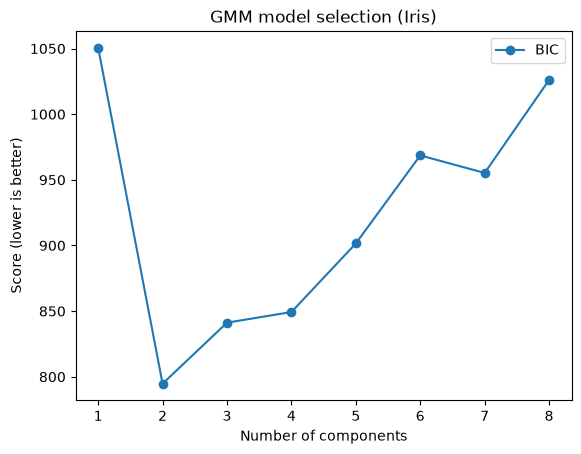

In [32]:
components = range(1, 9)
bics = []
aics = []
for c in components:
    gmm = GaussianMixture(n_components=c, covariance_type="full", random_state=42)
    gmm.fit(X_scaled)
    bics.append(gmm.bic(X_scaled))
   # aics.append(gmm.aic(X_scaled))

fig, ax = plt.subplots()
ax.plot(list(components), bics, marker="o", label="BIC")
ax.set_xlabel("Number of components")
ax.set_ylabel("Score (lower is better)")
ax.set_title("GMM model selection (Iris)")
ax.legend()
plt.show()

Let’s fit GMM with the number of components that looks best from the BIC.
(If unsure, try 3 for Iris.)

GMM labels (first 10): [1 1 1 1 1 1 1 1 1 1]


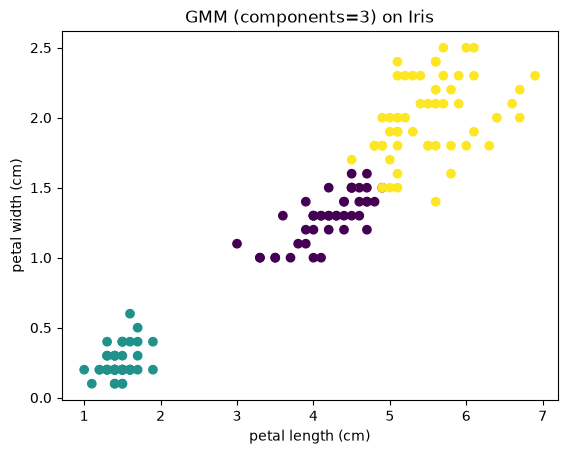

GMM silhouette score: 0.3741649186654123


In [33]:
best_c = 3  # you can change this after checking the BIC plot
gmm = GaussianMixture(n_components=best_c, covariance_type="full", random_state=0)
gmm_labels = gmm.fit_predict(X_scaled)

print("GMM labels (first 10):", gmm_labels[:10])

# Visualize in 2D
fig, ax = plt.subplots()
ax.scatter(X["petal length (cm)"], X["petal width (cm)"], c=gmm_labels)
ax.set_xlabel("petal length (cm)")
ax.set_ylabel("petal width (cm)")
ax.set_title(f"GMM (components={best_c}) on Iris")
plt.show()
silhouette_scores[best_c] = silhouette_score(X_scaled, gmm_labels)
print("GMM silhouette score:", silhouette_scores[best_c])

**Task (3–4 min).**  
Compute Silhoutte index for the Model Based clustering with the optimal number of clusters.

## 7) Silhouette score

Let’s compare all three methods side by side with the silhouette score.

In [36]:
def try_methods(X):
    # K-means (k=3)
    km = KMeans(n_clusters=3, n_init="auto", random_state=42).fit(X)
    km_labels = km.labels_
    km_s = silhouette_score(X, km_labels)

    # Agglomerative
    ac = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
    ac_labels = ac.labels_
    ac_s = silhouette_score(X, ac_labels)

    # GMM
    gmm = GaussianMixture(n_components=3, random_state=42).fit(X)
    gmm_labels = gmm.predict(X)
    gmm_s = silhouette_score(X, gmm_labels)

    print(f"Silhouette — KMeans: {km_s:.3f}, Agglomerative: {ac_s:.3f}, GMM: {gmm_s:.3f}")

try_methods(X_scaled)

Silhouette — KMeans: 0.480, Agglomerative: 0.447, GMM: 0.475


## 8) Summary

- **Hierarchical**: no need to pre‑choose `k` strictly; dendrogram can help visualize structure; linkage choice matters.

- **K‑means**: fast, simple; prefers roughly spherical clusters of similar size.

- **GMM**: probabilistic, flexible shapes via covariance; BIC/AIC help pick the number of components.

**Task:** try kmeans and model based clustering with **europejobs.csv**, experiment with the number of clusters/components, and compare with silhouette score (or other criteria).

            Agr  Min   Man   PS  Con    SI  Fin   SPS   TC
Belgium     3.3  0.9  27.6  0.9  8.2  19.1  6.2  26.6  7.2
Denmark     9.2  0.1  21.8  0.6  8.3  14.6  6.5  32.2  7.1
France     10.8  0.8  27.5  0.9  8.9  16.8  6.0  22.6  5.7
W.Germany   6.7  1.3  35.8  0.9  7.3  14.4  5.0  22.3  6.1
Ireland    23.2  1.0  20.7  1.3  7.5  16.8  2.8  20.8  6.1


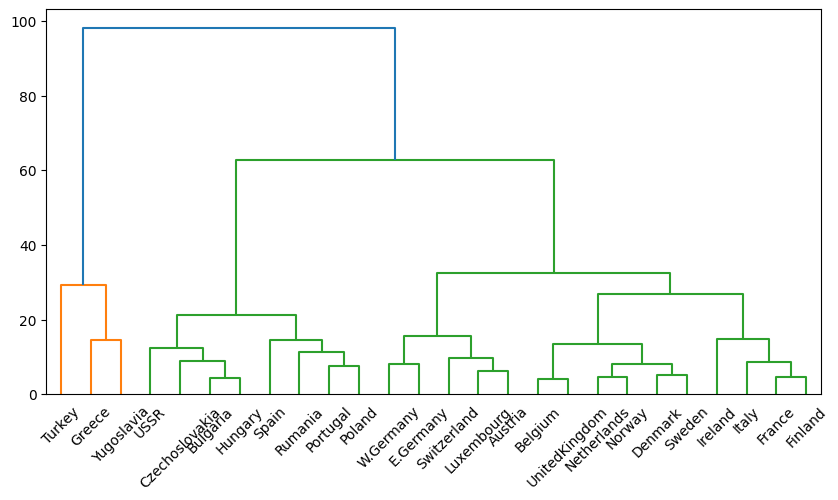

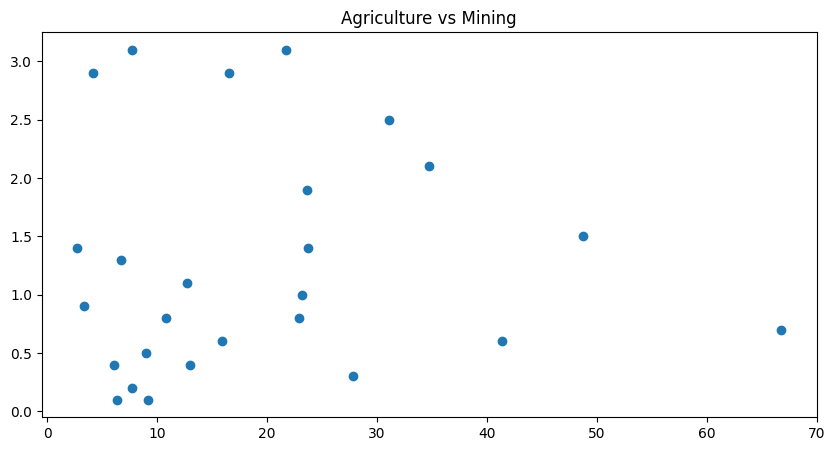

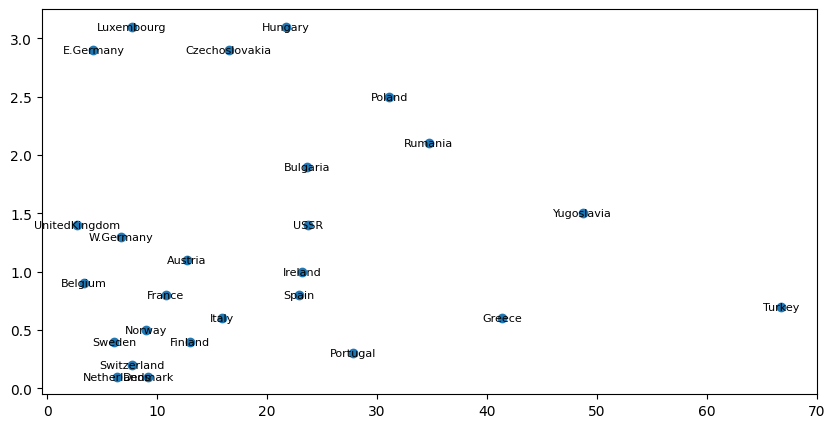

In [15]:
from pathlib import Path as PATH
path = PATH("../data/europejobs.csv")
jobs = pd.read_csv(path)    
print(jobs.head())
Z = linkage(jobs, method="ward")

plt.figure(figsize=(10, 5)) 
dendrogram(Z, labels=jobs.index)
plt.show()

plt.figure(figsize = (10,5))
plt.title("Agriculture vs Mining")
plt.plot(jobs.iloc[:, 0], jobs.iloc[:, 1], 'o')
plt.show()

#optional:

plt.figure(figsize = (10,5))

plt.scatter(jobs.iloc[:, 0], jobs.iloc[:, 1])

# add the index as a small label
for i in range(len(jobs)):
    plt.text(jobs.iloc[:,0].iloc[i], jobs.iloc[:,1].iloc[i], jobs.index[i],
             fontsize=8, ha="center", va="center")

plt.show()
